In [1]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ==========================================
# Cell 1: Import Library & Setup Environment
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Config tampilan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Memuat Dataset
file_path = 'top_insta_influencers_data[1].csv'
df = pd.read_csv(file_path)

print("=== Dataset Berhasil Dimuat ===")
df.head()

=== Dataset Berhasil Dimuat ===


,rank,channel_info,influence_score,posts,followers,avg_likes,60_day_eng_rate,new_post_avg_like,total_likes,country
0,1,cristiano,92,3.3k,475.8m,8.7m,1.39%,6.5m,29.0b,Spain
1,2,kyliejenner,91,6.9k,366.2m,8.3m,1.62%,5.9m,57.4b,United States
2,3,leomessi,90,0.89k,357.3m,6.8m,1.24%,4.4m,6.0b,NaN
3,4,selenagomez,93,1.8k,342.7m,6.2m,0.97%,3.3m,11.5b,United States
4,5,therock,91,6.8k,334.1m,1.9m,0.20%,665.3k,12.5b,United States


In [3]:
# ==========================================
# Cell 2: Cek Duplikat dan Data Kosong Awal
# ==========================================
print(f"Jumlah Data Duplikat: {df.duplicated().sum()}")
print("\nJumlah Data Kosong (Missing Values) Per Kolom:")
print(df.isnull().sum())

Jumlah Data Duplikat: 0

Jumlah Data Kosong (Missing Values) Per Kolom:
rank                  0
channel_info          0
influence_score       0
posts                 0
followers             0
avg_likes             0
60_day_eng_rate       0
new_post_avg_like     0
total_likes           0
country              62
dtype: int64


In [4]:
# ==========================================
# Cell 3: Fungsi Conversions & Data Cleaning
# ==========================================
def parse_number(val):
    """Mengubah string dengan notasi k, m, b, % menjadi angka numerik (float)"""
    if pd.isna(val):
        return np.nan
    val = str(val).strip().lower().replace('%', '')
    if val.endswith('b'):
        return float(val[:-1]) * 1e9
    elif val.endswith('m'):
        return float(val[:-1]) * 1e6
    elif val.endswith('k'):
        return float(val[:-1]) * 1e3
    try:
        return float(val)
    except:
        return np.nan

# Copy Dataframe
df_clean = df.copy()

# 1. Menangani Duplikat
df_clean = df_clean.drop_duplicates()

# 2. Imputasi Data Kosong pada Kolom 'country'
df_clean['country'] = df_clean['country'].fillna('Unknown')

# 3. Konversi Kolom String Notasi Ke Numerik (Float)
cols_to_convert = ['posts', 'followers', 'avg_likes', '60_day_eng_rate', 'new_post_avg_like', 'total_likes']
for col in cols_to_convert:
    df_clean[col] = df_clean[col].apply(parse_number)

# 4. Imputasi nilai missing pada 60_day_eng_rate (jika ada) menggunakan nilai median
df_clean['60_day_eng_rate'] = df_clean['60_day_eng_rate'].fillna(df_clean['60_day_eng_rate'].median())

print("=== Tipe Data Setelah Cleaning ===")
print(df_clean.dtypes)
df_clean.head()

=== Tipe Data Setelah Cleaning ===
rank                   int64
channel_info             str
influence_score        int64
posts                float64
followers            float64
avg_likes            float64
60_day_eng_rate      float64
new_post_avg_like    float64
total_likes          float64
country                  str
dtype: object


,rank,channel_info,influence_score,posts,followers,avg_likes,60_day_eng_rate,new_post_avg_like,total_likes,country
0,1,cristiano,92,3300.0,475800000.0,8700000.0,1.39,6500000.0,2.900000e+10,Spain
1,2,kyliejenner,91,6900.0,366200000.0,8300000.0,1.62,5900000.0,5.740000e+10,United States
2,3,leomessi,90,890.0,357300000.0,6800000.0,1.24,4400000.0,6.000000e+09,Unknown
3,4,selenagomez,93,1800.0,342700000.0,6200000.0,0.97,3300000.0,1.150000e+10,United States
4,5,therock,91,6800.0,334100000.0,1900000.0,0.20,665300.0,1.250000e+10,United States


In [7]:
import pandas as pd

# ==========================================
# Cell 4: Ringkasan Deskriptif (Statistical Summary)
# ==========================================
print("=== Ringkasan Statistik Kolom Numerik ===")

# Solusi: Ubah format float bawaan pandas
pd.options.display.float_format = '{:,.2f}'.format

# Tampilkan tanpa .style
display(df_clean.describe().T)

=== Ringkasan Statistik Kolom Numerik ===


,count,mean,std,min,25%,50%,75%,max
rank,200.00,100.50,57.88,1.00,50.75,100.50,150.25,200.00
influence_score,200.00,81.82,8.88,22.00,80.00,84.00,86.00,93.00
posts,200.00,"3,499.85","3,475.83",10.00,947.50,"2,100.00","5,025.00","17,500.00"
followers,200.00,"77,409,500.00","73,687,269.79","32,800,000.00","40,000,000.00","50,050,000.00","68,900,000.00","475,800,000.00"
avg_likes,200.00,"1,787,103.50","2,193,359.15","65,100.00","504,400.00","1,100,000.00","2,100,000.00","15,400,000.00"
60_day_eng_rate,200.00,1.90,3.32,0.01,0.41,0.88,2.03,26.41
new_post_avg_like,200.00,"1,208,132.50","1,858,321.85",0.00,"195,750.00","532,150.00","1,325,000.00","12,600,000.00"
total_likes,200.00,"3,658,112,500.00","5,561,938,629.08","18,300,000.00","996,850,000.00","2,000,000,000.00","3,900,000,000.00","57,400,000,000.00"


In [10]:
# ==========================================
# Cell 5: Tabel Agregasi Berdasarkan Negara
# ==========================================
country_summary = df_clean.groupby('country').agg(
    jumlah_influencer=('channel_info', 'count'),
    avg_influence_score=('influence_score', 'mean'),
    total_followers=('followers', 'sum'),
    avg_followers=('followers', 'mean'),
    avg_engagement_rate=('60_day_eng_rate', 'mean')
).sort_values(by='jumlah_influencer', ascending=False)

print("=== Agregasi Data Berdasarkan Negara (Top 10) ===")

# Buat salinan 10 data teratas agar data asli tidak berubah
df_display = country_summary.head(10).copy()

# Format setiap kolom secara manual menggunakan .map()
df_display['avg_influence_score'] = df_display['avg_influence_score'].map('{:.2f}'.format)
df_display['total_followers'] = df_display['total_followers'].map('{:,.0f}'.format)
df_display['avg_followers'] = df_display['avg_followers'].map('{:,.0f}'.format)
df_display['avg_engagement_rate'] = df_display['avg_engagement_rate'].map('{:.2f}%'.format)

# Tampilkan dataframe biasa tanpa .style
display(df_display)

=== Agregasi Data Berdasarkan Negara (Top 10) ===


,jumlah_influencer,avg_influence_score,total_followers,avg_followers,avg_engagement_rate
country,,,,,
United States,66,84.21,"7,147,700,000","108,298,485",1.40%
Unknown,62,82.19,"3,927,700,000","63,350,000",3.16%
Brazil,13,77.77,"735,900,000","56,607,692",0.67%
India,12,81.75,"677,400,000","56,450,000",2.37%
Indonesia,7,80.57,"313,300,000","44,757,143",0.25%
France,6,75.50,"269,000,000","44,833,333",0.71%
Spain,5,78.80,"739,300,000","147,860,000",0.78%
United Kingdom,4,78.25,"239,500,000","59,875,000",1.04%
Colombia,3,83.67,"156,100,000","52,033,333",0.73%


In [ ]:
# ==========================================
# Cell 6: Visualisasi EDA - Top 10 Negara Influencer
# ==========================================
plt.figure(figsize=(10, 5))
top_countries = country_summary.reset_index().head(10)
sns.barplot(data=top_countries, x='jumlah_influencer', y='country', palette='Blues_r')
plt.title('Top 10 Negara dengan Influencer Terbanyak dalam Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Influencer')
plt.ylabel('Negara')
plt.tight_layout()
plt.show()

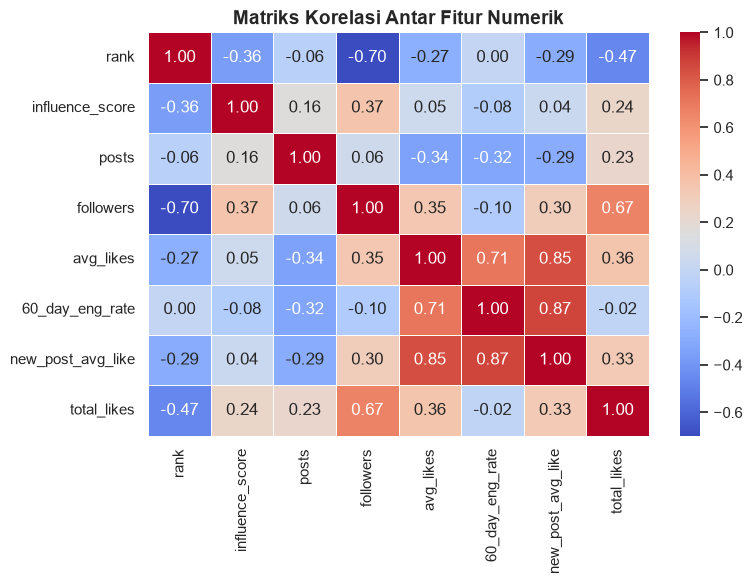

In [11]:
# ==========================================
# Cell 7: Visualisasi EDA - Matriks Korelasi
# ==========================================
plt.figure(figsize=(8, 6))
numeric_df = df_clean.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Antar Fitur Numerik', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# Cell 8: Ekspor Data Clean
# ==========================================
output_file = 'clean_top_insta_influencers.csv'
df_clean.to_csv(output_file, index=False)
print(f"Data bersih berhasil disimpan ke file: {output_file}")